In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Cargar las dos bases de datos
ventas = pd.read_excel("ventas.xlsx")
productos = pd.read_excel("productos.xlsx")

# Comprobar su tamaño y mostrar los primeros registros
print(f"Ventas: {ventas.shape[0]} filas y {ventas.shape[1]} columnas")
print(f"Productos: {productos.shape[0]} filas y {productos.shape[1]} columnas")

display(ventas.head())
display(productos.head())

Ventas: 1000 filas y 7 columnas
Productos: 100 filas y 5 columnas


,id_venta,fecha,id_producto,id_vendedor,unidades,precio_unitario,region
0,1,2024-04-12,3,19,13,403.79,Sur
1,2,2024-12-14,33,12,2,380.50,Sur
2,3,2024-09-27,6,18,4,222.96,Sur
3,4,2024-04-16,50,6,6,61.34,Sur
4,5,2024-03-12,10,18,5,427.55,Sur


,id_producto,nombre_producto,categoria,costo_unitario,stock
0,1,Producto_1,Electrónica,269.38,970
1,2,Producto_2,Hogar,187.14,567
2,3,Producto_3,Alimentos,246.85,969
3,4,Producto_4,Alimentos,140.31,963
4,5,Producto_5,Ropa,229.96,264


In [2]:
# PUNTO 2. Exploración y diagnóstico de los datos

# Tipos de datos y cantidad de valores no nulos
print("INFORMACIÓN DE VENTAS")
ventas.info()

print("\nINFORMACIÓN DE PRODUCTOS")
productos.info()

# Valores nulos por columna
print("\nNULOS EN VENTAS")
display(ventas.isna().sum().to_frame("cantidad_nulos"))

print("NULOS EN PRODUCTOS")
display(productos.isna().sum().to_frame("cantidad_nulos"))

# Filas completamente repetidas
print("Filas duplicadas en ventas:", ventas.duplicated().sum())
print("Filas duplicadas en productos:", productos.duplicated().sum())

# Identificadores repetidos: requieren revisión antes de eliminar registros
print("ID de venta repetidos:", ventas["id_venta"].duplicated().sum())
print("ID de producto repetidos:",
      productos["id_producto"].duplicated().sum())

# Revisar fechas sin modificar todavía la columna original
fechas_revisadas = pd.to_datetime(ventas["fecha"], errors="coerce")

fechas_invalidas = ventas["fecha"].notna() & fechas_revisadas.isna()
fechas_fuera_2024 = (
    fechas_revisadas.notna()
    & (fechas_revisadas.dt.year != 2024)
)

print("\nFechas faltantes:", ventas["fecha"].isna().sum())
print("Fechas no interpretables:", fechas_invalidas.sum())
print("Fechas fuera de 2024:", fechas_fuera_2024.sum())
print("Primera fecha válida:", fechas_revisadas.min())
print("Última fecha válida:", fechas_revisadas.max())

if fechas_invalidas.any() or fechas_fuera_2024.any():
    print("\nVENTAS CON FECHAS QUE REQUIEREN REVISIÓN")
    display(ventas.loc[fechas_invalidas | fechas_fuera_2024])

# Comprobar que los productos vendidos existen en el catálogo
productos_sin_coincidencia = (
    ventas["id_producto"].notna()
    & ~ventas["id_producto"].isin(productos["id_producto"])
)

print("\nVentas con producto fuera del catálogo:",
      productos_sin_coincidencia.sum())

INFORMACIÓN DE VENTAS
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         1000 non-null   int64         
 1   fecha            1000 non-null   datetime64[us]
 2   id_producto      1000 non-null   int64         
 3   id_vendedor      1000 non-null   int64         
 4   unidades         1000 non-null   int64         
 5   precio_unitario  1000 non-null   float64       
 6   region           1000 non-null   str           
dtypes: datetime64[us](1), float64(1), int64(4), str(1)
memory usage: 54.8 KB

INFORMACIÓN DE PRODUCTOS
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_producto      100 non-null    int64  
 1   nombre_producto  100 non-null    str    
 2   categoria        100 n

,cantidad_nulos
id_venta,0
fecha,0
id_producto,0
id_vendedor,0
unidades,0
precio_unitario,0
region,0


NULOS EN PRODUCTOS


,cantidad_nulos
id_producto,0
nombre_producto,0
categoria,0
costo_unitario,0
stock,0


Filas duplicadas en ventas: 0
Filas duplicadas en productos: 0
ID de venta repetidos: 0
ID de producto repetidos: 0

Fechas faltantes: 0
Fechas no interpretables: 0
Fechas fuera de 2024: 0
Primera fecha válida: 2024-01-01 00:00:00
Última fecha válida: 2024-12-30 00:00:00

Ventas con producto fuera del catálogo: 0


### 2. Exploración y limpieza de datos

Se revisaron 1,000 registros de ventas y 100 productos. No se encontraron valores nulos, filas duplicadas, identificadores de venta repetidos ni identificadores de producto repetidos en el catálogo.

Las fechas se reconocieron correctamente y están comprendidas entre el 1 de enero y el 30 de diciembre de 2024. Además, todos los productos registrados en ventas tienen correspondencia en el catálogo.

Por estos motivos, no fue necesario eliminar registros ni imputar valores para las inconsistencias revisadas. Se conservaron las observaciones originales.

In [3]:
# PUNTO 3. Unión de ventas y productos

ventas_completas = ventas.merge(
    productos,
    on="id_producto",
    how="left",
    validate="many_to_one",
    indicator=True,
    sort=False
)

# Verificar que cada venta encontró su producto
assert ventas_completas["_merge"].eq("both").all(), \
    "Hay ventas sin correspondencia en productos."

# Verificar que la unión conservó el número de ventas
assert len(ventas_completas) == len(ventas), \
    "La unión modificó el número de ventas."

# Retirar la columna auxiliar de verificación
ventas_completas = ventas_completas.drop(columns="_merge")

print("Unión realizada correctamente.")
print("Filas:", ventas_completas.shape[0])
print("Columnas:", ventas_completas.shape[1])

display(ventas_completas.head())

Unión realizada correctamente.
Filas: 1000
Columnas: 11


,id_venta,fecha,id_producto,id_vendedor,unidades,precio_unitario,region,nombre_producto,categoria,costo_unitario,stock
0,1,2024-04-12,3,19,13,403.79,Sur,Producto_3,Alimentos,246.85,969
1,2,2024-12-14,33,12,2,380.50,Sur,Producto_33,Hogar,148.39,271
2,3,2024-09-27,6,18,4,222.96,Sur,Producto_6,Alimentos,275.65,183
3,4,2024-04-16,50,6,6,61.34,Sur,Producto_50,Electrónica,208.97,757
4,5,2024-03-12,10,18,5,427.55,Sur,Producto_10,Ropa,75.62,488


In [4]:
# PUNTO 4. Calcular ingresos y crear arreglos NumPy

# Ingreso por venta = unidades × precio unitario
ventas["ingreso"] = (
    ventas["unidades"] * ventas["precio_unitario"]
).round(2)

ventas_completas["ingreso"] = (
    ventas_completas["unidades"]
    * ventas_completas["precio_unitario"]
).round(2)

unidades = ventas["unidades"].to_numpy()
precio_unitario = ventas["precio_unitario"].to_numpy()
ingreso = ventas["ingreso"].to_numpy()

print("Primeros 5 valores de cada arreglo:")
print("Unidades:", unidades[:5])
print("Precio unitario:", precio_unitario[:5])
print("Ingreso:", ingreso[:5])

# PUNTO 5. Construir la matriz: una fila por venta
matriz_ventas = np.column_stack(
    (unidades, precio_unitario, ingreso)
)

print("\nDimensiones de la matriz:", matriz_ventas.shape)
print("Orden de columnas: unidades, precio_unitario, ingreso")

# PUNTO 6. Seleccionar filas y un ingreso específico
print("\nPrimeras 10 filas:")
print(matriz_ventas[:10])

# Python cuenta desde 0: la fila 50 corresponde al índice 49
ingreso_fila_50 = matriz_ventas[49, 2]

print(f"\nIngreso de la fila 50: {ingreso_fila_50:,.2f}")

Primeros 5 valores de cada arreglo:
Unidades: [13  2  4  6  5]
Precio unitario: [403.79 380.5  222.96  61.34 427.55]
Ingreso: [5249.27  761.    891.84  368.04 2137.75]

Dimensiones de la matriz: (1000, 3)
Orden de columnas: unidades, precio_unitario, ingreso

Primeras 10 filas:
[[1.30000e+01 4.03790e+02 5.24927e+03]
 [2.00000e+00 3.80500e+02 7.61000e+02]
 [4.00000e+00 2.22960e+02 8.91840e+02]
 [6.00000e+00 6.13400e+01 3.68040e+02]
 [5.00000e+00 4.27550e+02 2.13775e+03]
 [3.00000e+00 5.51400e+01 1.65420e+02]
 [1.00000e+00 3.66660e+02 3.66660e+02]
 [4.00000e+00 4.86620e+02 1.94648e+03]
 [2.00000e+00 2.46950e+02 4.93900e+02]
 [5.00000e+00 1.55740e+02 7.78700e+02]]

Ingreso de la fila 50: 1,713.25


In [5]:
# PUNTO 7. Ventas con ingreso superior al promedio

# Calcular el promedio usando NumPy
ingreso_promedio = np.mean(ingreso)

# Condición lógica: estrictamente mayor al promedio
condicion = matriz_ventas[:, 2] > ingreso_promedio

# Crear una nueva matriz con las ventas que cumplen
matriz_superior_promedio = matriz_ventas[condicion]

cantidad_superior = matriz_superior_promedio.shape[0]
porcentaje_superior = cantidad_superior / len(matriz_ventas) * 100

print(f"Ingreso promedio por venta: {ingreso_promedio:,.2f}")
print(f"Ventas superiores al promedio: {cantidad_superior}")
print(f"Porcentaje del total: {porcentaje_superior:.2f}%")
print("Dimensiones de la nueva matriz:",
      matriz_superior_promedio.shape)

# Mostrar una vista de la matriz en formato de tabla
print("\nPrimeras 10 ventas que cumplen la condición:")
display(pd.DataFrame(
    matriz_superior_promedio[:10],
    columns=["unidades", "precio_unitario", "ingreso"]
))

Ingreso promedio por venta: 2,727.09
Ventas superiores al promedio: 401
Porcentaje del total: 40.10%
Dimensiones de la nueva matriz: (401, 3)

Primeras 10 ventas que cumplen la condición:


,unidades,precio_unitario,ingreso
0,13.0,403.79,5249.27
1,9.0,417.71,3759.39
2,18.0,485.17,8733.06
3,19.0,277.16,5266.04
4,12.0,373.30,4479.60
5,11.0,438.19,4820.09
6,15.0,410.00,6150.00
7,12.0,298.72,3584.64
8,12.0,228.45,2741.40
9,16.0,180.52,2888.32


In [6]:
# PUNTO 8. Ingresos por región, categoría y desempeño de vendedores

ingresos_region = (
    ventas_completas.groupby("region")["ingreso"]
    .sum()
    .sort_values(ascending=False)
)

ingresos_categoria = (
    ventas_completas.groupby("categoria")["ingreso"]
    .sum()
    .sort_values(ascending=False)
)

resumen_vendedores = (
    ventas_completas.groupby("id_vendedor")
    .agg(
        ingreso_total=("ingreso", "sum"),
        unidades_totales=("unidades", "sum")
    )
)

# Seleccionar todos los líderes, por si existen empates
lideres_monto = resumen_vendedores.loc[
    resumen_vendedores["ingreso_total"]
    == resumen_vendedores["ingreso_total"].max()
]

lideres_unidades = resumen_vendedores.loc[
    resumen_vendedores["unidades_totales"]
    == resumen_vendedores["unidades_totales"].max()
]

print(f"Ingreso total: {np.sum(ingreso):,.2f}")

print("\nINGRESOS POR REGIÓN")
display(ingresos_region.to_frame().round(2))

print("\nINGRESOS POR CATEGORÍA")
display(ingresos_categoria.to_frame().round(2))

print("\nVENDEDOR O VENDEDORES LÍDERES POR MONTO")
display(lideres_monto.round(2))

print("\nVENDEDOR O VENDEDORES LÍDERES POR UNIDADES")
display(lideres_unidades.round(2))

Ingreso total: 2,727,086.70

INGRESOS POR REGIÓN


,ingreso
region,
Sur,716657.04
Occidente,703627.64
Centro,691855.59
Norte,614946.43



INGRESOS POR CATEGORÍA


,ingreso
categoria,
Electrónica,857143.21
Alimentos,761217.78
Ropa,555966.84
Hogar,552758.87



VENDEDOR O VENDEDORES LÍDERES POR MONTO


,ingreso_total,unidades_totales
id_vendedor,,
4,179283.22,547



VENDEDOR O VENDEDORES LÍDERES POR UNIDADES


,ingreso_total,unidades_totales
id_vendedor,,
6,141948.0,598


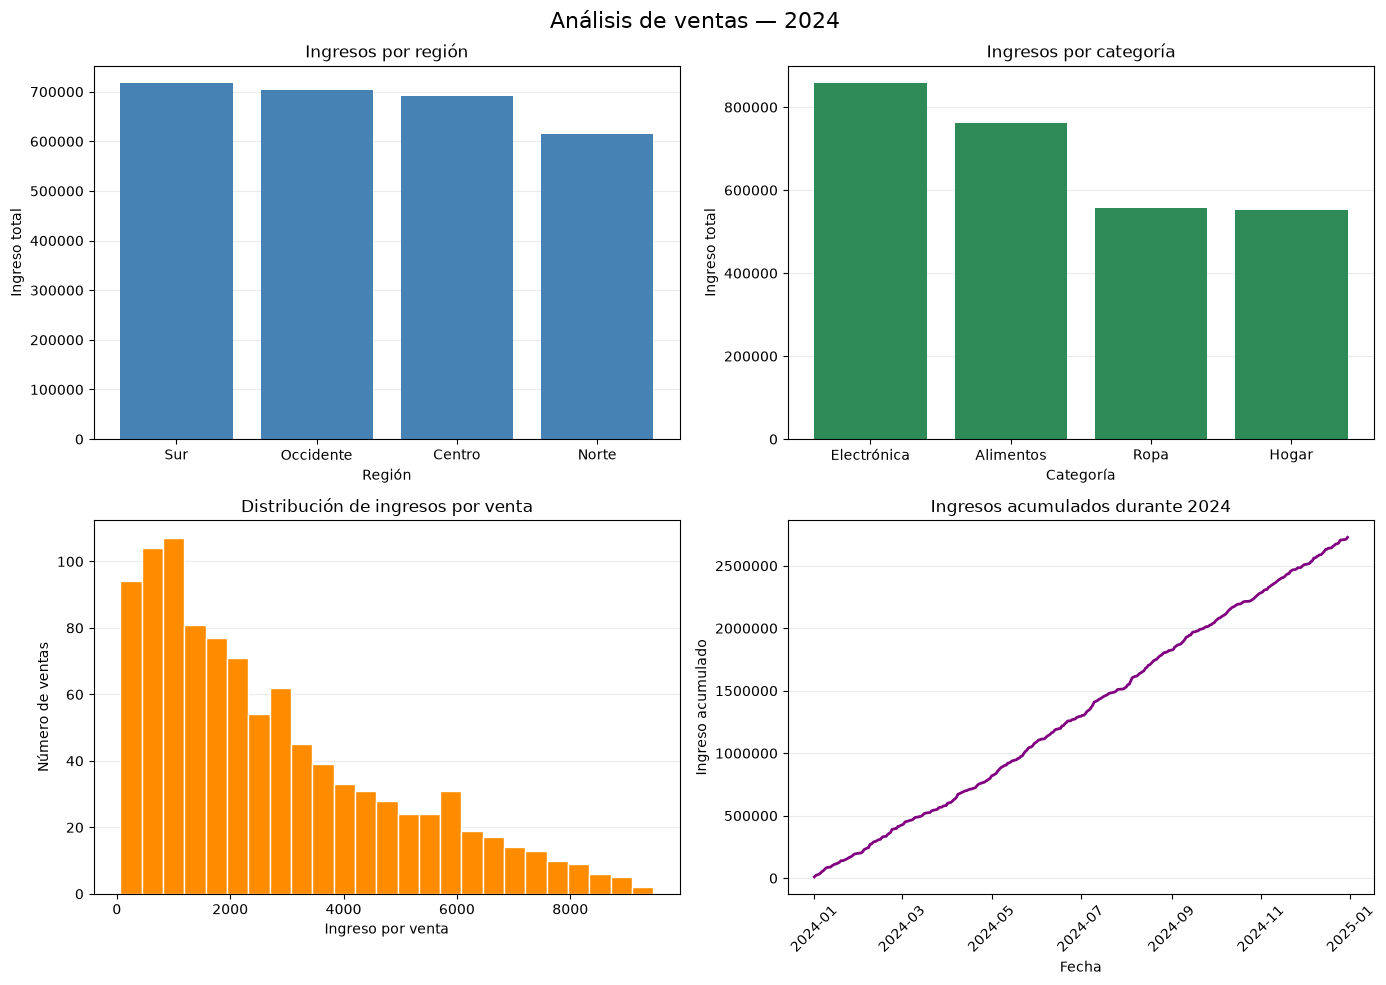

In [7]:
# Cuatro gráficas obligatorias

# Sumar ingresos por día y ordenar antes de acumular
ingresos_diarios = (
    ventas_completas
    .groupby(ventas_completas["fecha"].dt.normalize())["ingreso"]
    .sum()
    .sort_index()
)

ingresos_acumulados = ingresos_diarios.cumsum()

fig, ejes = plt.subplots(2, 2, figsize=(14, 10))

# a) Barras: ingresos por región
ejes[0, 0].bar(
    ingresos_region.index,
    ingresos_region.values,
    color="steelblue"
)
ejes[0, 0].set_title("Ingresos por región")
ejes[0, 0].set_xlabel("Región")
ejes[0, 0].set_ylabel("Ingreso total")

# b) Barras: ingresos por categoría
ejes[0, 1].bar(
    ingresos_categoria.index,
    ingresos_categoria.values,
    color="seagreen"
)
ejes[0, 1].set_title("Ingresos por categoría")
ejes[0, 1].set_xlabel("Categoría")
ejes[0, 1].set_ylabel("Ingreso total")

# c) Histograma: distribución de ingresos por venta
ejes[1, 0].hist(
    ingreso,
    bins=25,
    color="darkorange",
    edgecolor="white"
)
ejes[1, 0].set_title("Distribución de ingresos por venta")
ejes[1, 0].set_xlabel("Ingreso por venta")
ejes[1, 0].set_ylabel("Número de ventas")

# d) Línea: ingresos acumulados en orden cronológico
ejes[1, 1].plot(
    ingresos_acumulados.index,
    ingresos_acumulados.values,
    color="purple",
    linewidth=2
)
ejes[1, 1].set_title("Ingresos acumulados durante 2024")
ejes[1, 1].set_xlabel("Fecha")
ejes[1, 1].set_ylabel("Ingreso acumulado")
ejes[1, 1].tick_params(axis="x", labelrotation=45)

for eje in ejes.flat:
    eje.ticklabel_format(axis="y", style="plain", useOffset=False)
    eje.grid(axis="y", alpha=0.25)
    eje.set_axisbelow(True)

fig.suptitle("Análisis de ventas — 2024", fontsize=16)
plt.tight_layout()
plt.show()


,Observados,Simulados
Cantidad de datos,1000.00,1000.00
Media,2727.09,2665.33
Mediana,2125.98,2740.29
Desviación estándar muestral,2137.36,2114.32
Mínimo,60.67,-5070.89
Máximo,9467.13,9521.45
Cantidad de ingresos negativos,0.00,105.00


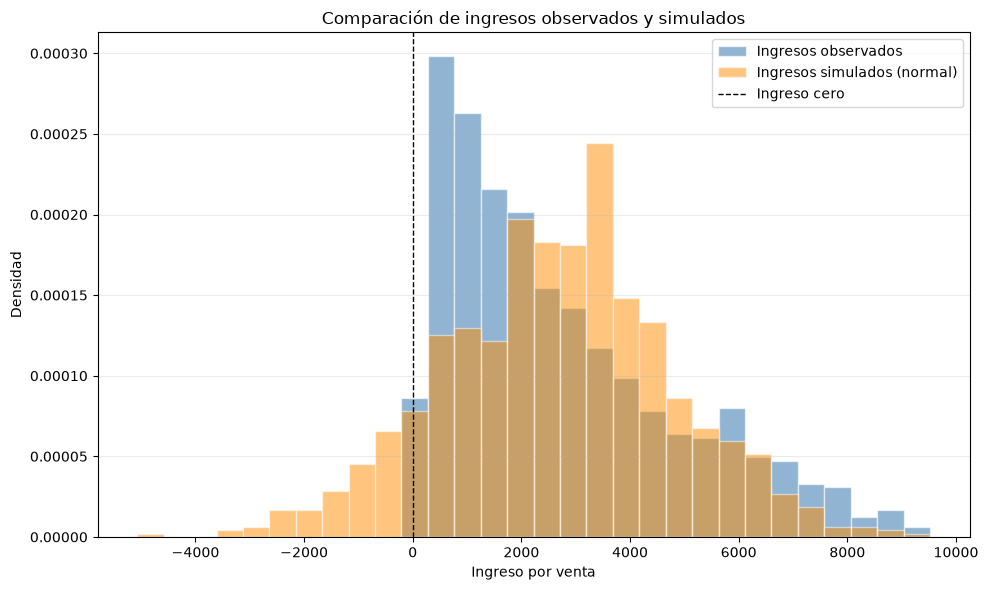

In [8]:
# PUNTO 9. Simulación de ingresos con distribución normal

media_observada = np.mean(ingreso)
desviacion_observada = np.std(ingreso, ddof=1)

# Semilla fija para obtener los mismos resultados al ejecutar de nuevo
generador = np.random.default_rng(42)

ingresos_simulados = generador.normal(
    loc=media_observada,
    scale=desviacion_observada,
    size=1000
)

# Comparación de estadísticas
comparacion = pd.DataFrame({
    "Observados": [
        len(ingreso),
        np.mean(ingreso),
        np.median(ingreso),
        np.std(ingreso, ddof=1),
        np.min(ingreso),
        np.max(ingreso),
        np.sum(ingreso < 0)
    ],
    "Simulados": [
        len(ingresos_simulados),
        np.mean(ingresos_simulados),
        np.median(ingresos_simulados),
        np.std(ingresos_simulados, ddof=1),
        np.min(ingresos_simulados),
        np.max(ingresos_simulados),
        np.sum(ingresos_simulados < 0)
    ]
}, index=[
    "Cantidad de datos",
    "Media",
    "Mediana",
    "Desviación estándar muestral",
    "Mínimo",
    "Máximo",
    "Cantidad de ingresos negativos"
])

display(comparacion.round(2))

# Usar los mismos intervalos para comparar las distribuciones
intervalos = np.histogram_bin_edges(
    np.concatenate((ingreso, ingresos_simulados)),
    bins=30
)

plt.figure(figsize=(10, 6))

plt.hist(
    ingreso,
    bins=intervalos,
    density=True,
    alpha=0.6,
    color="steelblue",
    label="Ingresos observados",
    edgecolor="white"
)

plt.hist(
    ingresos_simulados,
    bins=intervalos,
    density=True,
    alpha=0.5,
    color="darkorange",
    label="Ingresos simulados (normal)",
    edgecolor="white"
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Ingreso cero"
)

plt.title("Comparación de ingresos observados y simulados")
plt.xlabel("Ingreso por venta")
plt.ylabel("Densidad")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### 10. Conclusiones

Se analizaron 1,000 ventas y un catálogo de 100 productos. No se encontraron valores nulos, filas duplicadas ni fechas inválidas o fuera de 2024. La unión mediante `id_producto` conservó todas las ventas y encontró correspondencia para cada producto.

**Resultados comerciales.** El ingreso total fue de 2,727,086.70 unidades monetarias. La región Sur obtuvo el mayor ingreso, con 716,657.04, mientras que Norte registró el menor, con 614,946.43. Por categoría, Electrónica encabezó los ingresos con 857,143.21 y Hogar presentó el menor monto, con 552,758.87. Estos resultados corresponden a ingresos por ventas; no representan utilidades.

**Desempeño de vendedores.** El vendedor con ID 4 lideró por monto, con 179,283.22, mientras que el vendedor con ID 6 lideró por volumen, con 598 unidades. Por ello, conviene evaluar ambos indicadores: vender más unidades no implica necesariamente generar el mayor ingreso.

**Distribución de ingresos.** El ingreso promedio por venta fue de 2,727.09 y la mediana de 2,125.98. Un total de 401 ventas, equivalente al 40.10 %, superó el promedio. El histograma muestra una concentración de ventas de menor monto y una cola hacia ingresos elevados, consistente con una distribución asimétrica hacia la derecha.

**Comportamiento temporal.** Los ingresos acumulados aumentaron durante el año hasta alcanzar el total registrado. Este aumento refleja la suma progresiva de ingresos positivos; por sí solo no demuestra que las ventas de cada mes hayan crecido respecto al mes anterior.

**Simulación normal.** Se generaron 1,000 valores utilizando la media y la desviación estándar muestral de los ingresos observados. La media simulada fue de 2,665.33 y su desviación estándar de 2,114.32, cercanas a los valores observados de 2,727.09 y 2,137.36, respectivamente. Sin embargo, la simulación produjo 105 ingresos negativos (10.5 %), frente a ninguno en los datos reales. Además, su forma aproximadamente simétrica contrasta con la asimetría observada. Por tanto, aunque reproduce aproximadamente la media y la dispersión, el supuesto normal presenta limitaciones para representar estos ingresos. Esta comparación es descriptiva y no constituye una prueba formal de normalidad.

**Áreas de oportunidad.** Se propone investigar el menor ingreso de Norte y de la categoría Hogar, considerando cantidad de operaciones, unidades vendidas, precios y disponibilidad de productos antes de decidir acciones comerciales. También sería útil estudiar las prácticas de los vendedores líderes y complementar el análisis con costos y márgenes para evaluar la rentabilidad.